In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split

import numpy as np
import matplotlib.pyplot as plt

from Metaparameters.multioutput_ann import accuracy

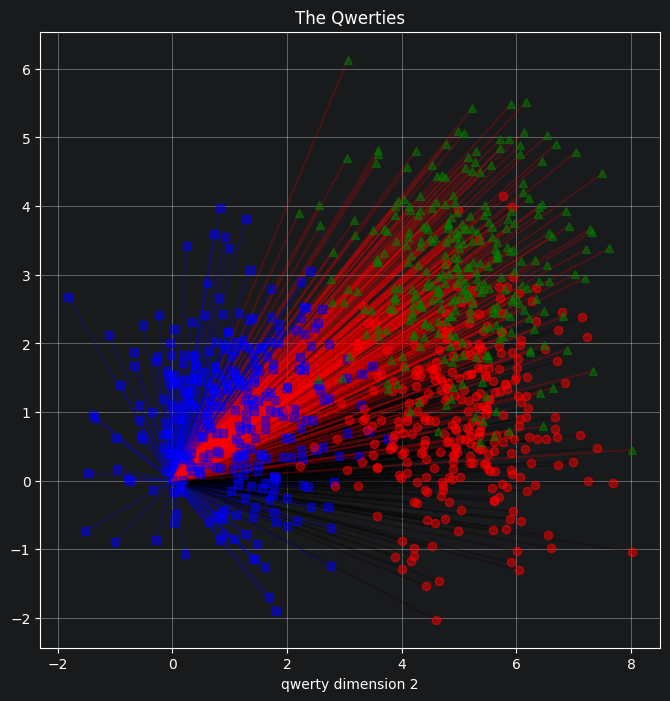

In [2]:
nPerClust = 300
blur = 1

A = [1, 1]
B = [5, 1]
C = [4, 3]

a = [ A[0] + np.random.randn(nPerClust)*blur, A[1]+np.random.randn(nPerClust)*blur]
b = [ B[0] + np.random.randn(nPerClust)*blur, B[1]+np.random.randn(nPerClust)*blur]
c = [ B[0] + np.random.randn(nPerClust)*blur, C[1]+np.random.randn(nPerClust)*blur]

labels_np = np.hstack(( np.zeros((nPerClust)),
                        np.ones((nPerClust)),
                        1+np.ones((nPerClust))
                        ))

data_np = np.hstack((a,b,c)).T

data = torch.tensor(data_np).float()
labels = torch.tensor(labels_np).long()

fig = plt.figure(figsize=(8,8))
color = 'bkr'
for i in range(len(data)):
    plt.plot([0, data[i,0]], [0,data[i,1]], color=color[labels[i]], alpha=.2)

plt.plot( data[np.where(labels==0)[0], 0], data[np.where(labels==0)[0], 1], 'bs', alpha=.5)
plt.plot( data[np.where(labels==1)[0], 0], data[np.where(labels==1)[0], 1], 'ro', alpha=.5)
plt.plot( data[np.where(labels==2)[0], 0], data[np.where(labels==2)[0], 1], 'g^', alpha=.5)

plt.grid(color=[.9, .9, .9])
plt.title('The Qwerties')
plt.xlabel('qwerty dimension 1')
plt.xlabel('qwerty dimension 2')
plt.show()

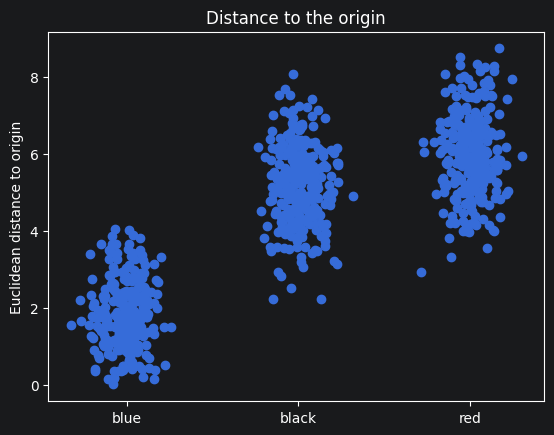

In [3]:
dist2orig = torch.sqrt( data[:,0]**2 + data[:, 1]**2 )

plt.plot(labels+torch.randn(900)/10, dist2orig, 'o')
plt.xticks([0,1,2], ['blue', 'black', 'red'])
plt.ylabel('Euclidean distance to origin')
plt.title('Distance to the origin')
plt.show()

In [4]:
dataAug = torch.cat((data, dist2orig.view(len(data), 1)), axis=1)

print(data.shape)
print(dataAug.shape)
print(' ')

print(dataAug)

torch.Size([900, 2])
torch.Size([900, 3])
 
tensor([[ 0.3180,  0.3981,  0.5095],
        [ 0.7068,  1.3233,  1.5003],
        [-0.1171,  0.1475,  0.1883],
        ...,
        [ 4.6500,  2.7655,  5.4102],
        [ 7.2027,  2.9551,  7.7854],
        [ 3.5060,  3.6569,  5.0661]])


In [5]:
train_data, test_data, train_labels, test_labels = train_test_split(dataAug, labels, test_size=0.2, random_state=42)

train_data = torch.utils.data.TensorDataset(train_data, train_labels)
test_data = torch.utils.data.TensorDataset(test_data, test_labels)

batchsize = 16
train_loader = DataLoader(train_data, batch_size=batchsize, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batchsize, shuffle=True)

In [8]:
def createTheQwertyNet(useExtraFeature=False):

    class qwertyNet(nn.Module):
        def __init__(self):
            super().__init__()

            if useExtraFeature:
                self.input = nn.Linear(3,8)
            else:
                self.input = nn.Linear(2,8)

            self.fc1 = nn.Linear(8,8)

            self.output = nn.Linear(8,3)

        def forward(self, x):
            if not useExtraFeature:
                x = x[:, :2]

            x = F.relu( self.input(x) )
            x = F.relu( self.fc1(x) )
            return self.output(x)

    net = qwertyNet()
    lossfun = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(net.parameters(), lr=0.001)

    return net, lossfun, optimizer

In [11]:
print('Using augmented feature: ')
net = createTheQwertyNet(True)[0]
net(next(iter(train_loader))[0])

print('Not using augmented feature: ')
net = createTheQwertyNet(False)[0]
net(next(iter(train_loader))[0])

Using augmented feature: 
Not using augmented feature: 


tensor([[-1.6213,  1.0579, -0.1852],
        [-0.3387,  0.3944,  0.1834],
        [-1.5546,  0.9787, -0.3536],
        [-0.5890,  0.5252,  0.0878],
        [-1.5114,  0.9671, -0.3027],
        [-1.3247,  0.8696, -0.2575],
        [-0.3848,  0.4161,  0.1648],
        [-0.6682,  0.5620,  0.0861],
        [-2.2102,  1.3247, -0.6295],
        [-2.0595,  1.2535, -0.5698],
        [-0.4463,  0.4585,  0.1328],
        [-1.8356,  1.1251, -0.4788],
        [-0.4979,  0.4679,  0.0867],
        [-1.4339,  0.9426, -0.2305],
        [-1.4248,  0.9171, -0.2993],
        [-0.5544,  0.5013,  0.0764]], grad_fn=<AddmmBackward0>)

In [18]:
def function2trainTheModel(useExtraFeature=False):

    numepochs = 200

    net, lossfun, optimizer = createTheQwertyNet(useExtraFeature)

    losses = torch.zeros(numepochs)
    trainAcc = []
    testAcc = []

    for epochi in range(numepochs):

        batchAcc = []
        batchLoss = []
        for X, y in train_loader:
            yHat = net(X)
            loss = lossfun(yHat, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            batchLoss.append(loss.item())

            matches = torch.argmax(yHat, axis=1) == y
            matchesNumeric = matches.float()
            acuracyPct = 100*torch.mean(matchesNumeric)

        trainAcc.append( np.mean(batchAcc) )

        losses[epochi] = np.mean(batchLoss)

        X, y = next(iter(test_loader))
        with torch.no_grad():
            yHat = net(X)

        testAcc.append( 100*torch.mean((torch.argmax(yHat, axis=1)==y).float()) )

    return trainAcc, testAcc, losses, net

In [23]:
def plotTheResults():

    yHat = net(dataAug)
    predictions = torch.argmax(yHat, axis=1)
    accuracy = (predictions == labels).float()

    accuracyByGroup = np.zeros(3)
    for i in range(3):
        accuracyByGroup[i] = 100*torch.mean(accuracy[labels == i] )

    fig, ax = plt.subplots(2, 2, figsize=(10,6))

    ax[0,0].plot(losses.detach())
    ax[0,0].set_ylabel('Loss')
    ax[0,0].set_xlabel('Epoch')
    ax[0,0].set_title('Losses')

    ax[0,1].plot(trainAcc, label='Train Accuracy')
    ax[0,1].plot(testAcc, label='Test Accuracy')
    ax[0,1].set_ylabel('Accuracy')
    ax[0,1].set_xlabel('Epoch')
    ax[0,1].set_title('Accuracy')
    ax[0,1].legend()

    ax[1,0].bar(range(3), accuracyByGroup)
    ax[1,0].set_ylim([np.min(accuracyByGroup)-5, np.max(accuracyByGroup)+5])
    ax[1,0].set_xticks([0,1,2])
    ax[1,0].set_xlabel('Group')
    ax[1,0].set_ylabel('Accuracy')
    ax[1,0].set_title('Accuracy by group')

    colorShapes = ['bs', 'ko', 'g^']
    for i in range(3):
        ax[1,1].plot(dataAug[labels==i, 0], dataAug[labels==i, 1], colorShapes[i],          alpha=.3, label=f'Group {i}')
        idxErr = (accuracy==0) & (labels==i)
        ax[1,1].plot(dataAug[idxErr, 0], dataAug[idxErr, 1], 'rx')

    ax[1,1].set_title('All groups')
    ax[1,1].set_xlabel('qwerty dimension 1')
    ax[1,1].set_ylabel('qwerty diemnsino 2')
    ax[1,1].legend()

    plt.tight_layout()

Final accuracy:  93.75


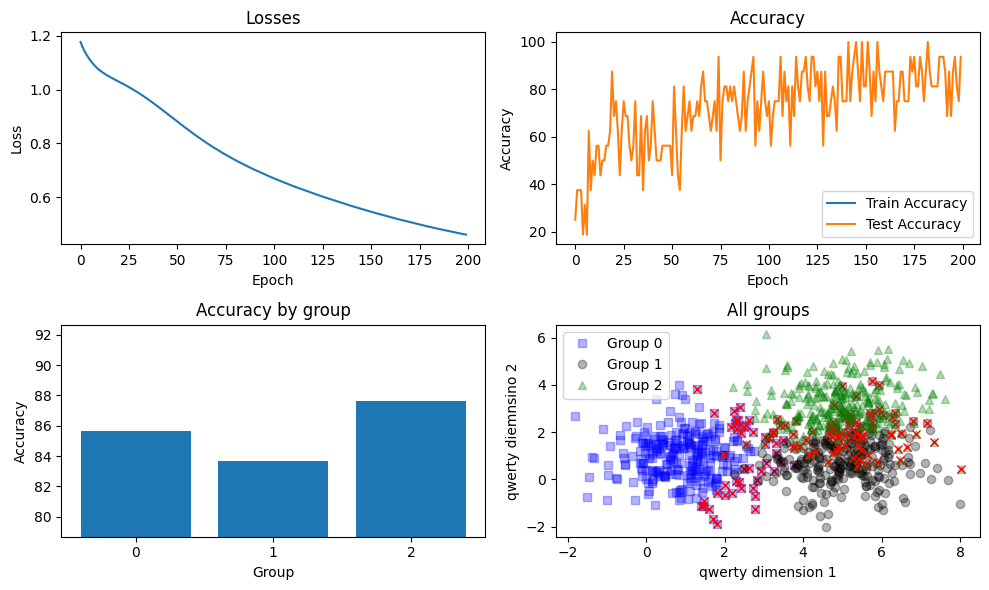

In [26]:
trainAcc, testAcc, losses, net = function2trainTheModel(False)
print('Final accuracy: ', testAcc[-1].item())
plotTheResults()

Final accuracy:  93.75


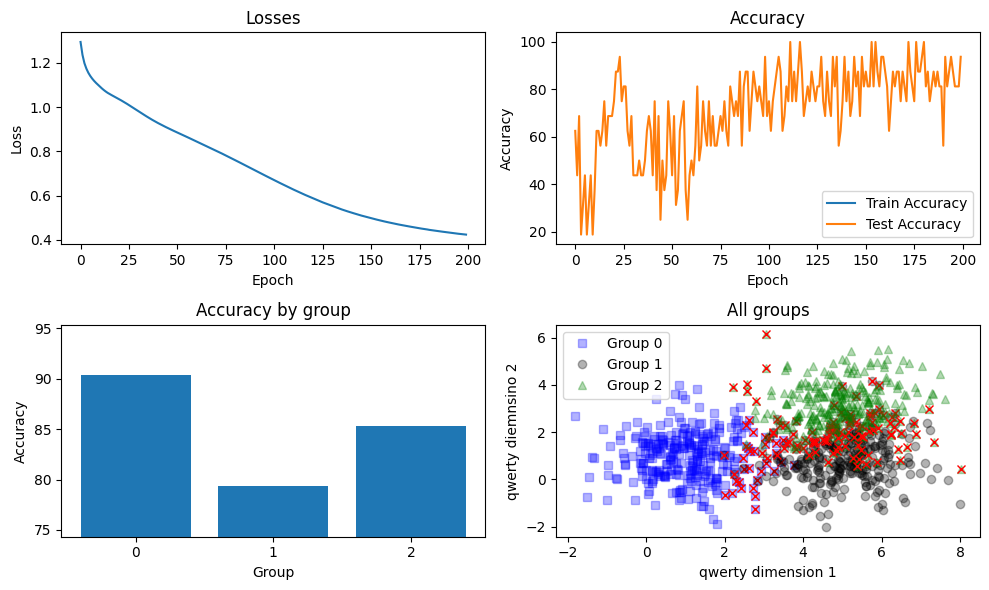

In [27]:
trainAcc, testAcc, losses, net = function2trainTheModel(True)
print('Final accuracy: ', testAcc[-1].item())
plotTheResults()

In [28]:
finalacc2 = np.zeros(10)
finalacc3 = np.zeros(10)

for i in range(10):
    finalacc2[i] = function2trainTheModel(False)[1][-1]
    finalacc3[i] = function2trainTheModel(False)[1][-1]

print( np.round(np.vstack((finalacc2, finalacc3)).T, 2) )

from scipy import stats
t, p = stats.ttest_ind(finalacc3, finalacc2)
print('\n\nt=%.2f, p=%.2f' %(t,p))

/home/alexpy/PycharmProjects/Deep-Learning-Notes/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/alexpy/PycharmProjects/Deep-Learning-Notes/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


[[ 81.25  87.5 ]
 [100.    87.5 ]
 [100.    87.5 ]
 [ 81.25  87.5 ]
 [100.    93.75]
 [ 87.5  100.  ]
 [ 87.5   87.5 ]
 [ 68.75  87.5 ]
 [ 87.5   56.25]
 [ 81.25 100.  ]]


t=0.00, p=1.00
